# 07 · Is smoothing the reason ETS wins?

ETS beat every other method one quarter ahead. Session 6 showed that starting from the latest quarter isn't the whole reason. ETS also **smooths**: it averages over past quarters instead of trusting one. This session tests that with one new simple rule.

**B4 (fixed in advance, no variants):** latest known quarter × the **average** of the same step over the last three years (a geometric mean of three ratios). B3 used only last year's step.

In Excel (revenue in column B, latest known quarter in row 21, the next quarter):
```
=B21*GEOMEAN(B18/B17;B14/B13;B10/B9)
```

**Hypothesis (fixed in the chat before running; see PROGRESS.md for a timing note):** if smoothing explains ETS's lead, B4 ties ETS (about 10 of 20) and beats B3 mostly for seasonal and cyclical companies.

**Main tests (fixed):** (1) one quarter ahead, and (2) full year: in how many of the 20 companies does B4 beat ETS? Two-sided sign tests.

Same setup as Sessions 4–6: 20 companies, fiscal quarters, per-company origins, 65-day rule, first-reported revenue; Alphabet without the Motorola targets. Code: `src/smoothing.py`, `src/evaluate_smoothing.py` (`run` computed B4 on the full grid in a few seconds).

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from companies import TYPES
from smoothing import worked_example
from evaluate_types import best_rules, load_forecasts
from evaluate_smoothing import (ALL, OUT as B4_FORECASTS, all_methods, per_company, main_tests, win_table,
                                by_type, all_horizons, effect_of_2020, without_2020_diagnostic,
                                year_2020, leak_check)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
f = all_methods()
t = per_company(f, best_rules(load_forecasts()))

## 1. Worked example: Mattel at its first origin ($m)

In [2]:
worked_example("Mattel")

Mattel, first origin 2013Q1: we pretend it is 2013-06-04; latest known quarter 2013Q1 = 995.6

h = 1, target 2013Q2:
    2012Q2 / 2012Q1 = 1,158.7 / 928.4 = 1.2480
    2011Q2 / 2011Q1 = 1,161.7 / 951.9 = 1.2204
    2010Q2 / 2010Q1 = 1,018.5 / 880.1 = 1.1573
    geometric mean = (1.2480 x 1.2204 x 1.1573)^(1/3) = 1.2080
    B4 = 995.6 x 1.2080 = 1,202.7    (B3 = 1,242.5 uses only 1.2480;  ETS = 1,212.7)

h = 2, target 2013Q3:
    2012Q3 / 2012Q1 = 2,077.8 / 928.4 = 2.2379
    2011Q3 / 2011Q1 = 1,998.8 / 951.9 = 2.0999
    2010Q3 / 2010Q1 = 1,833.1 / 880.1 = 2.0828
    geometric mean = (2.2379 x 2.0999 x 2.0828)^(1/3) = 2.1391
    B4 = 995.6 x 2.1391 = 2,129.7    (B3 = 2,228.1 uses only 2.2379;  ETS = 2,058.6)

h = 3, target 2013Q4:
    2012Q4 / 2012Q1 = 2,255.9 / 928.4 = 2.4298
    2011Q4 / 2011Q1 = 2,153.8 / 951.9 = 2.2627
    2010Q4 / 2010Q1 = 2,124.6 / 880.1 = 2.4140
    geometric mean = (2.4298 x 2.2627 x 2.4140)^(1/3) = 2.3676
    B4 = 995.6 x 2.3676 = 2,357.2    (B3 = 2,419.1 uses

**What this shows:** for Mattel in 2013, 2012's steps were the biggest of the three years. B3, which copies 2012, sits highest; B4 averages the three years down. One quarter ahead, B4 ($1,202.7 m) lands next to ETS ($1,212.7 m), while B3 says $1,242.5 m.

## 2. Leak check (all counts must be 0)

In [3]:
g = pd.read_csv(B4_FORECASTS, parse_dates=["cutoff", "latest_used_filed"])
for col in ["origin", "target"]:
    g[col] = pd.PeriodIndex(g[col], freq="Q")
print("years of steps used:", g["years_used"].value_counts().sort_index().to_dict())
leak_check(g)

years of steps used: {2: 4, 3: 4032}


forecasts                                 4036
uses a quarter public after the cutoff       0
target not after the origin                  0
missing B4                                   0
dtype: int64

## 3. Main tests
A **sign test** treats each company as a coin toss: if B4 and ETS were equally good, each would win about half. Two-sided. **Caveat:** companies share shocks (2020 above all), so they aren't fully independent and the p-values are somewhat too optimistic.

In [4]:
main_tests(t).round(4)

,wins,sign test p (two-sided)
comparison,,
one quarter ahead: B4 beats ETS,6/20,0.12
full year: B4 beats ETS,7/20,0.26


**What this shows:** B4 beats ETS for **6 of 20** companies one quarter ahead (p = 0.12) and **7 of 20** for the full year (p = 0.26). Neither split is clearly different from a coin toss, so B4, unlike B3 (4 of 20, p = 0.01) and LightGBM, is **not reliably worse than ETS**. But it doesn't tie ETS either: 6 is well short of the 10 the hypothesis expected. Smoothing the step closes part of the gap, not all of it.

## 4. All comparisons, with wins by type (descriptive)

In [5]:
win_table(t).round(4)

,wins,sign test p (two-sided),Seasonal,Growth tech,Cyclical industrial,FMCG
comparison,,,,,,
one quarter ahead: B4 beats ETS,6/20,0.12,0/5,4/5,1/5,1/5
one quarter ahead: B4 beats B3,16/20,0.01,2/5,4/5,5/5,5/5
one quarter ahead: B4 beats best rule,16/20,0.01,4/5,5/5,3/5,4/5
full year: B4 beats ETS,7/20,0.26,0/5,5/5,0/5,2/5
full year: B4 beats B3,14/20,0.12,4/5,2/5,4/5,4/5
full year: B4 beats best rule,10/20,1.00,3/5,3/5,1/5,3/5


**What this shows:** B4 is the strongest simple rule so far. One quarter ahead it beats B3 for 16 of 20 companies and each company's old best rule for 16 of 20 (both p = 0.01). By type, B4 beats B3 for all 5 cyclical and all 5 FMCG companies but only 2 of 5 seasonal ones, so the hypothesis's "mostly seasonal and cyclical" holds for cyclicals but not for seasonal companies. For the full year B4 beats B3 for 14 of 20 but the old best rule for only 10 of 20, a coin flip.

## 5. Per company and by type (MAPE %)

In [6]:
t[[c for c in t.columns if ":" not in c]].round(2)

,type,best rule,h1 B4,h1 ETS,h1 B3,h1 best rule,FY B4,FY ETS,FY B3,FY best rule
Mattel,Seasonal,B1,7.81,7.49,7.68,8.89,8.27,6.93,9.00,6.36
Hasbro,Seasonal,B2,11.37,10.14,10.95,10.25,11.08,9.74,10.75,11.08
Williams-Sonoma,Seasonal,B2,4.19,3.66,4.13,5.65,5.58,4.04,5.72,6.69
Best Buy,Seasonal,B2,5.05,4.07,5.14,6.03,6.12,4.63,6.66,7.63
Macy's,Seasonal,B2,5.86,5.25,6.09,8.86,7.46,6.10,9.57,9.67
Alphabet,Growth tech,B2,3.22,3.41,3.80,5.66,5.33,5.88,6.07,7.19
Microsoft,Growth tech,B2,4.07,3.83,4.23,5.68,5.18,6.44,5.72,6.44
Salesforce,Growth tech,B2,1.70,2.39,1.71,2.65,3.14,4.31,2.89,3.04
Netflix,Growth tech,B2,1.92,2.14,2.15,3.59,3.91,5.41,3.51,4.31
Adobe,Growth tech,B2,2.49,2.63,2.31,3.35,3.99,5.11,3.38,3.87


In [7]:
by_type(t).round(2)

,h1 ETS,h1 B4,h1 B3,h1 best rule,FY ETS,FY B4,FY B3,FY best rule
type,,,,,,,,
Seasonal,6.12,6.86,6.80,7.93,6.29,7.70,8.34,8.29
Growth tech,2.88,2.68,2.84,4.19,5.43,4.31,4.31,4.97
Cyclical industrial,5.75,6.51,7.39,7.75,8.79,10.99,11.69,9.88
FMCG,2.95,3.20,3.79,3.85,3.26,3.65,4.27,3.61


**What this shows:** for **growth tech**, B4 is better than ETS (one quarter ahead 2.68 vs 2.88 %, full year 4.31 vs 5.43 %): averaging three years of steps suits steady growth. For **seasonal** companies, smoothing doesn't help (B4 6.86 vs B3 6.80 %), and both stay behind ETS (6.12 %). For **cyclicals**, B4 improves a lot on B3 (6.51 vs 7.39 %) but is still behind ETS (5.75 %), with PACCAR worst (10.2 vs 8.0 %).

## 6. All horizons (mean MAPE over all forecasts, %)

In [8]:
all_horizons(f).round(2)

baseline,ETS,B4,B3,B2,B1,B0
h,,,,,,
1,4.41,4.78,5.18,6.95,10.33,11.87
2,6.25,6.79,7.33,8.45,10.40,15.70
3,7.67,8.38,8.95,9.55,10.46,14.57
4,8.87,9.90,10.65,10.50,10.54,10.54


**What this shows:** across all forecasts, B4 is the best simple rule at every horizon (4.8, 6.8, 8.4 and 9.9 %), ahead of B3 and of the old rules even four quarters ahead. ETS is still lower at every horizon (4.4, 6.3, 7.7 and 8.9 %).

## 7. The 2020 steps inside the 3-year average
For 2021–2023 forecasts, B4's average includes a step that touches 2020. How much does that cost? We compare B4 with the same average leaving the 2020 steps out, one quarter ahead. This is a diagnostic, not a rule: B4 stays as fixed.

In [9]:
effect_of_2020().round(2)

,B4,B4 without 2020 steps,forecasts,cost of the 2020 steps (points)
type,,,,
Seasonal,9.53,7.44,65.00,2.10
Growth tech,2.86,2.59,65.00,0.27
Cyclical industrial,7.30,5.41,65.00,1.89
FMCG,4.07,3.98,65.00,0.09
all,5.94,4.85,260.00,1.09


**What this shows:** for 2021–2023 forecasts, the 2020 step inside B4's average costs about **2.1 points for seasonal companies and 1.9 points for cyclicals**, but only 0.3 points for growth companies and 0.1 for FMCG (1.1 points on average over 260 one-quarter-ahead forecasts). A 3-year average keeps a shock in its memory for three years.

**Post-hoc diagnostic (found after seeing the results, so not a finding):** how would B4 compare with ETS one quarter ahead if the 2020 steps were left out of its average?

In [10]:
without_2020_diagnostic(f).round(2)

mean h1 MAPE, B4                                   4.78
mean h1 MAPE, B4 without 2020 steps                4.51
mean h1 MAPE, ETS                                  4.41
companies where B4 beats ETS                       6.00
companies where B4 without 2020 steps beats ETS   10.00
dtype: float64

**What this shows:** leaving the 2020 steps out would bring B4 to 4.51 % on average (ETS: 4.41 %), and to 10 of 20 companies against ETS, a tie. **But this was found after seeing the results**, and choosing to drop the steps that hurt is exactly the kind of after-the-fact tuning the project rules forbid. It's a hypothesis to test on new data ("B4 ignoring known shock years ties ETS"), not a finding.

## 8. Targets in 2020 (h = 1 MAPE, targets ending in calendar 2020 vs other years)

In [11]:
year_2020(f).round(1)

baseline               B3                B4               ETS            
when                 2020 other years  2020 other years  2020 other years
type                                                                     
Seasonal            17.30        6.00 16.20        6.20 13.60        5.60
Growth tech          3.70        2.80  3.40        2.60  3.80        2.80
Cyclical industrial 18.20        6.50 18.60        5.50 17.30        4.80
FMCG                 4.10        3.80  4.20        3.10  4.90        2.80

**What this shows:** for quarters in 2020 itself, B4 did better than ETS for growth (3.4 vs 3.8 %) and FMCG companies (4.2 vs 4.9 %) and worse for seasonal (16.3 vs 13.6 %) and cyclical ones (18.6 vs 17.3 %). In the shock year, starting from a recent quarter helps steady businesses and hurts volatile ones.

## 9. Summary chart
One-quarter-ahead MAPE per company, grouped by type: ETS, B4 and B3.

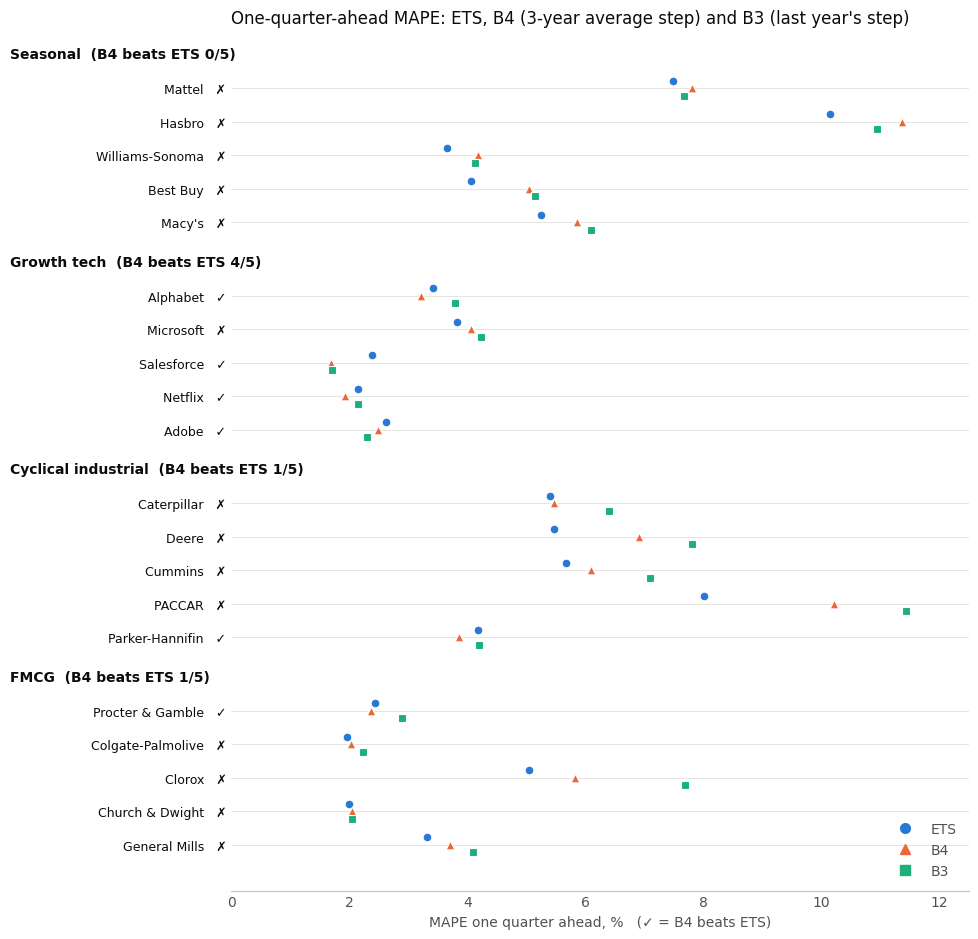

In [12]:
ETSC, B4C, B3C = "#2a78d6", "#eb6834", "#1baf7a"     # default palette slots 1-3
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
STYLE = {"ETS": (ETSC, "o", "h1 ETS"), "B4": (B4C, "^", "h1 B4"), "B3": (B3C, "s", "h1 B3")}
OFFSET = {"ETS": -0.22, "B4": 0.0, "B3": 0.22}
LIMIT = 12.5
rows, y = [], 0
for ty in TYPES:
    for c in [c for c in ALL if t.loc[c, "type"] == ty]:
        rows.append((y, c)); y += 1
    y += 1.2
fig, ax = plt.subplots(figsize=(10, 9.5))
for yy, c in rows:
    ax.hlines(yy, 0, LIMIT, color=GRID, lw=0.6, zorder=0)
    for m, (col, mk, field) in STYLE.items():
        ax.scatter(t.loc[c, field], yy + OFFSET[m], color=col, marker=mk, s=40, edgecolor="white", lw=0.8, zorder=3)
ax.set_yticks([r[0] for r in rows], [f"{c}   {'✓' if t.loc[c, 'h1: B4 beats ETS'] else '✗'}" for _, c in rows],
              fontsize=9, color=INK)
ax.invert_yaxis()
for ty in TYPES:
    ys = [yy for yy, c in rows if t.loc[c, "type"] == ty]
    ax.text(-0.3, min(ys) - 0.9, f"{ty}  (B4 beats ETS {int(t[t['type'] == ty]['h1: B4 beats ETS'].sum())}/5)",
            transform=ax.get_yaxis_transform(), color=INK, fontsize=10, fontweight="bold", ha="left")
ax.set_xlim(0, LIMIT)
ax.set_xlabel("MAPE one quarter ahead, %   (✓ = B4 beats ETS)", color=MUTED)
ax.tick_params(axis="x", colors=MUTED, length=0); ax.tick_params(axis="y", length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
handles = [plt.Line2D([], [], color=col, marker=mk, ls="", markersize=7, label=m) for m, (col, mk, _) in STYLE.items()]
ax.legend(handles=handles, frameon=False, loc="lower right", labelcolor=MUTED)
ax.set_title("One-quarter-ahead MAPE: ETS, B4 (3-year average step) and B3 (last year's step)",
             loc="left", color=INK, fontsize=12, pad=14)
fig.tight_layout()
plt.show()

**What this shows:** for growth companies, the orange triangles (B4) sit left of the blue circles (ETS) in four of five rows. For seasonal companies, B4 and B3 sit together, right of ETS. For cyclicals and FMCG, B4 has moved well left of B3 (green squares) but not past ETS, except for Parker-Hannifin and P&G.

## Summary

| Test (fixed in advance) | B4 wins | Sign test p |
|---|---|---|
| One quarter ahead: B4 beats ETS | 6 of 20 | 0.12 |
| Full year: B4 beats ETS | 7 of 20 | 0.26 |

**Plainly:** smoothing explains **part** of ETS's lead. Averaging three years of steps makes B4 the best simple rule in the project:
- One quarter ahead it beats B3 and each company's old best rule for 16 of 20 companies.
- It's the best simple rule at every horizon.
- Unlike B3 and LightGBM, it isn't reliably worse than ETS.
- For growth companies it beats ETS, both next quarter and for the full year.

But it doesn't tie ETS (6 of 20, not about 10). Seasonal companies don't benefit at all. A post-hoc look suggests the 2020 steps in its average cost much of the remaining gap; that's a hypothesis for new data, not a finding.

The bars stay: ETS one quarter ahead and, for the full year, ETS or the best simple rule. B4 is now the simple rule to beat.